
# Lab 7: Fast Fourier Transform (FFT)

 **Example 1** : Chord - musical sound: Do mayor. Done in class.

![Do mayor](https://upload.wikimedia.org/wikipedia/commons/7/79/Major_chord_on_C.png)

Load the Nota_CM_piano.mp3 file from a Do mayor sound:
1. Do the FFT using scipy and Numpy rutines (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?


 **Exercise 1** : Do the FFT for an Imagen

Choose an Imagen

1. Do the FFT using scipy (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?
3. Do the inverse FFT and reconstruc the original imagene. <br> Do you get a similar result? Compare the original and the reconstructed signal.


In [2]:
pip install librosa


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 3.0 MB/s  0:00:01m 13.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 4.5 MB/s  0:00:13s eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 2.7 MB/s  0:00:03m 29.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 725.5 kB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14/14 [librosa]━ 13/14 [librosa]earn]ile]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


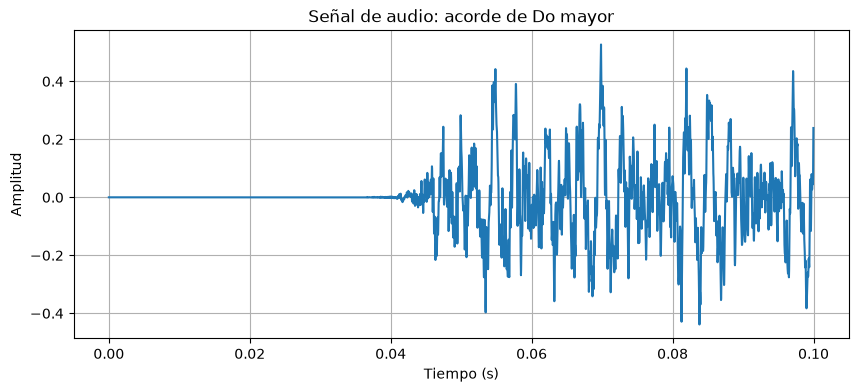

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import librosa
from scipy import interpolate
import scipy.integrate as integrate
from scipy.fft import fft, fftfreq

#audio
signal, sr = librosa.load('Nota_CM_piano.mp3', sr=None)

#fragmento de 0.1 segundos
N = int(0.1 * sr)
t = np.arange(N) / sr
y = signal[:N]

# Grafica
plt.figure(figsize=(10, 4))
plt.plot(t, y)
plt.title('Señal de audio: acorde de Do mayor')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

/tmp/ipykernel_6703/1473496251.py:17: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  ARew = integrate.quad(
/tmp/ipykernel_6703/1473496251.py:22: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  AImw = integrate.quad(
/tmp/ipykernel_6703/1473496251.py:22: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  AImw = integrate.quad(
/tmp/ipykernel_6703/1473496251.py:17: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the i

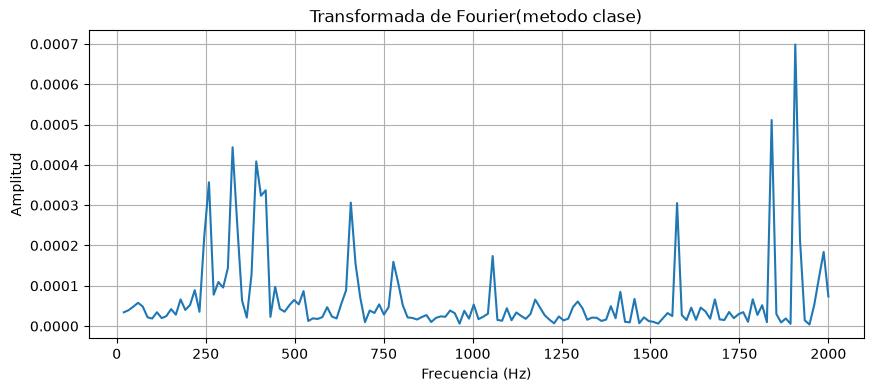

In [2]:


# Base compleja de Fourie
def g(t, w):
    return 1./(2*np.pi) * np.exp(-1j*2*np.pi*w*t)

# Rutina FT(x,y) 
def FT(x, y):
    f_interp = interpolate.interp1d(
        x, y, kind='cubic', fill_value='extrapolate'
    )
    ft = lambda t: f_interp(t)

    t_int = np.linspace(x.min(), x.max(), 400)
    w = np.linspace(20, 2000, 150)

    df = []
    for wi in w:
        ARew = integrate.quad(
            lambda ti: ft(ti)*g(ti, wi).real,
            t_int.min(), t_int.max()
        )[0]

        AImw = integrate.quad(
            lambda ti: ft(ti)*g(ti, wi).imag,
            t_int.min(), t_int.max()
        )[0]

        AMP = np.sqrt(ARew**2 + AImw**2)
        ANG = np.arctan2(AImw, ARew)
        df.append([wi, ARew, AImw, AMP, ANG])

    return pd.DataFrame(df, columns=['w', 'ReTw', 'ImTw', 'AMP', 'ANG'])

df_FT = FT(t, y)

# Grafica
plt.figure(figsize=(10, 4))
plt.plot(df_FT['w'], df_FT['AMP'])
plt.title('Transformada de Fourier(metodo clase)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

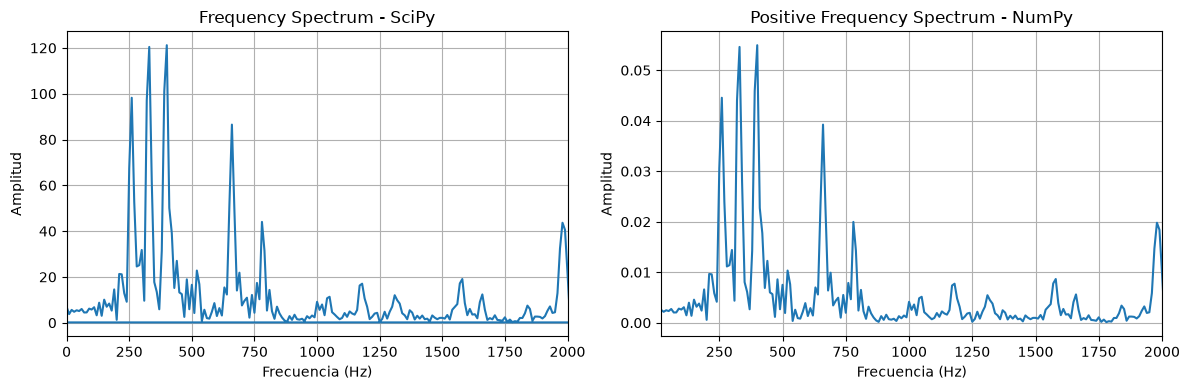

In [3]:
# FFT con SciPy
N = len(y)
yf_scipy = fft(y)
xf = fftfreq(N, 1/sr)

# FFT con NumPy
yf_numpy = np.fft.fft(y)

# Graficar el espectro con SciPy y NumPy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(xf, np.abs(yf_scipy))
plt.title('Frequency Spectrum - SciPy')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 2000)
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(xf[:N//2], 2.0/N * np.abs(yf_numpy[:N//2]))
plt.title('Positive Frequency Spectrum - NumPy')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(20, 2000)
plt.grid()

plt.tight_layout()
plt.show()


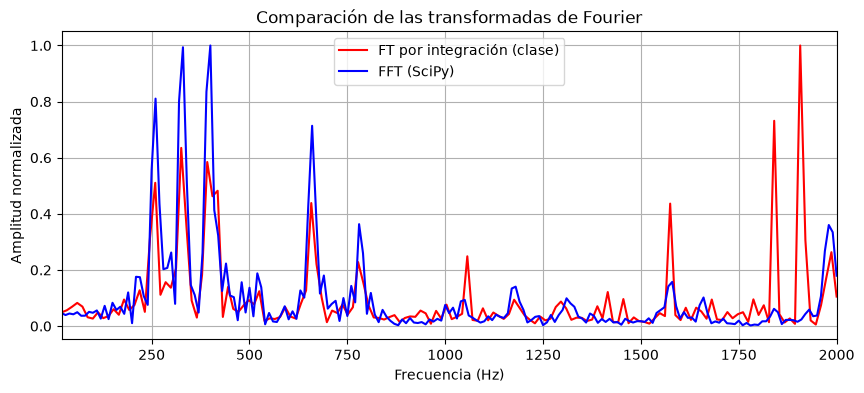

In [4]:
# FFT: frecuencias positivas
mask = (xf >= 20) & (xf <= 2000)
amp_fft = np.abs(yf_scipy[mask])

# Normalizar ambas amplitudes para comparar sus formas
amp_FT_norm = df_FT.AMP / df_FT.AMP.max()
amp_fft_norm = amp_fft / amp_fft.max()

plt.figure(figsize=(10, 4))

plt.plot(df_FT.w, amp_FT_norm, 'r-', label='FT por integración (clase)')
plt.plot(xf[mask], amp_fft_norm, 'b-', label='FFT (SciPy)')

plt.title('Comparación de las transformadas de Fourier')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud normalizada')
plt.xlim(20, 2000)
plt.grid()
plt.legend()
plt.show()

Los dos métodos presentan resultados similares, ya que identifican varios picos en frecuencias cercanas. Sin embargo, existen diferencias en las amplitudes y en algunos picos, especialmente en las frecuencias más altas. Esto indica que ambos métodos permiten reconocer las principales frecuencias del audio, aunque no producen resultados exactamente iguales debido a las diferencias entre la integración numérica y el cálculo mediante FFT.

/tmp/ipykernel_6703/3556228546.py:17: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  ARew = integrate.quad(
/tmp/ipykernel_6703/3556228546.py:22: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  AImw = integrate.quad(
/tmp/ipykernel_6703/3556228546.py:22: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one

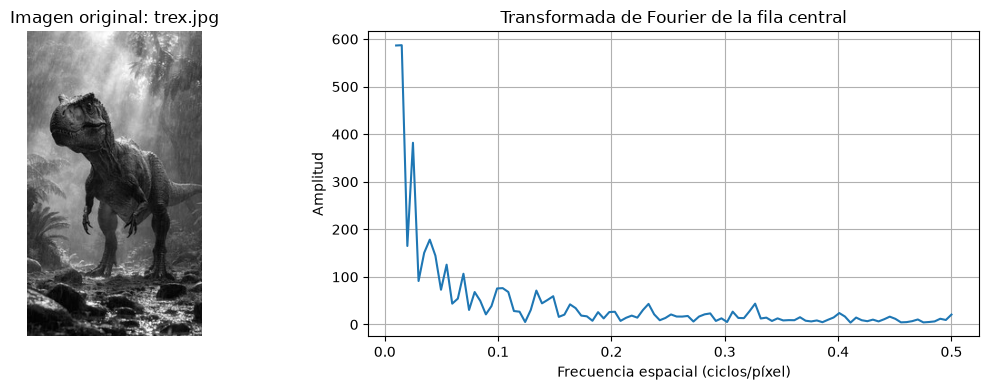

In [13]:
from scipy import interpolate, integrate

# Base compleja de Fourier de clase
def g(t, w):
    return 1/(2*np.pi) * np.exp(-1j*2*np.pi*w*t)

# Rutina FT modificada 
def FT_modificada(x, y, freq_min=0.01, freq_max=0.5, num_freqs=100):
    f_interp = interpolate.interp1d(
        x, y, kind='linear', fill_value='extrapolate'
    )

    w = np.linspace(freq_min, freq_max, num_freqs)
    df = []

    for wi in w:
        ARew = integrate.quad(
            lambda ti: f_interp(ti)*g(ti, wi).real,
            x.min(), x.max()
        )[0]

        AImw = integrate.quad(
            lambda ti: f_interp(ti)*g(ti, wi).imag,
            x.min(), x.max()
        )[0]

        AMP = np.sqrt(ARew**2 + AImw**2)
        ANG = np.arctan2(AImw, ARew)

        df.append([wi, ARew, AImw, AMP, ANG])

    return pd.DataFrame(df, columns=['w', 'ReTw', 'ImTw', 'AMP', 'ANG'])


# Cargar imagen
nombre_imagen = 'trex.jpg'
imagen_color = plt.imread(nombre_imagen)

# Convertir a escala de grises
if len(imagen_color.shape) == 3:
    imagen = np.mean(imagen_color[:, :, :3], axis=2)
else:
    imagen = imagen_color

imagen = imagen.astype(float)

# Tomar la fila horizontal central
fila_media = imagen.shape[0] // 2
senal_1d_imagen = imagen[fila_media, :]

# Coordenadas de los píxeles
x_pixeles = np.arange(len(senal_1d_imagen))

# Aplicar la transformada por integración numérica
df_img_1d = FT_modificada(
    x_pixeles,
    senal_1d_imagen,
    freq_min=0.01,
    freq_max=0.5,
    num_freqs=100
)

# Graficas
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen original: trex.jpg')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.plot(df_img_1d['w'], df_img_1d['AMP'])
plt.title('Transformada de Fourier de la fila central')
plt.xlabel('Frecuencia espacial (ciclos/píxel)')
plt.ylabel('Amplitud')
plt.grid()

plt.tight_layout()
plt.show()


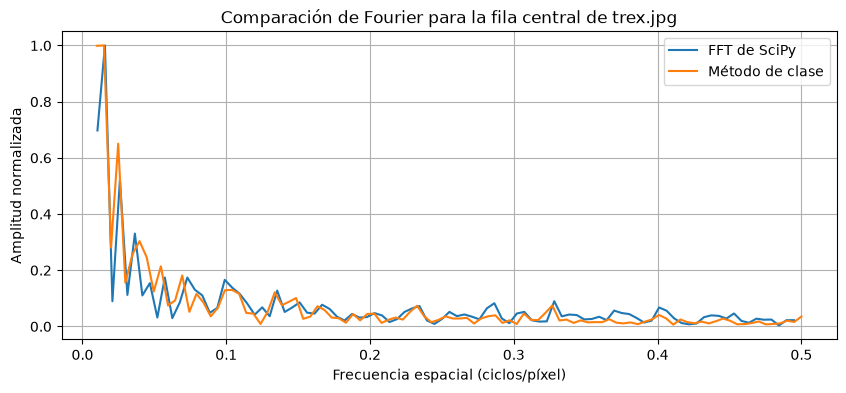

In [14]:
from scipy.fft import fft, fftfreq

# FFT de la fila central
N_img = len(senal_1d_imagen)

yf_img = fft(senal_1d_imagen)

# Frecuencias espaciales en ciclos/píxel
xf_img = fftfreq(N_img, d=1)

# frecuencias positivas entre 0.01 y 0.5
mascara_img = (xf_img >= 0.01) & (xf_img <= 0.5)

# Amplitudes de ambos métodos
AMP_FFT_img = np.abs(yf_img[mascara_img])
AMP_FT_img = df_img_1d['AMP'].to_numpy()

# Normalizaion
AMP_FFT_img = AMP_FFT_img / np.max(AMP_FFT_img)
AMP_FT_img = AMP_FT_img / np.max(AMP_FT_img)


# Grafica compracion
plt.figure(figsize=(10, 4))

plt.plot(
    xf_img[mascara_img],
    AMP_FFT_img,
    label='FFT de SciPy'
)

plt.plot(
    df_img_1d['w'],
    AMP_FT_img,
    label='Método de clase'
)

plt.title('Comparación de Fourier para la fila central de trex.jpg')
plt.xlabel('Frecuencia espacial (ciclos/píxel)')
plt.ylabel('Amplitud normalizada')
plt.legend()
plt.grid()

plt.show()

Los resultados son similares, ya que ambos métodos muestran una distribución de frecuencias y picos semejantes.

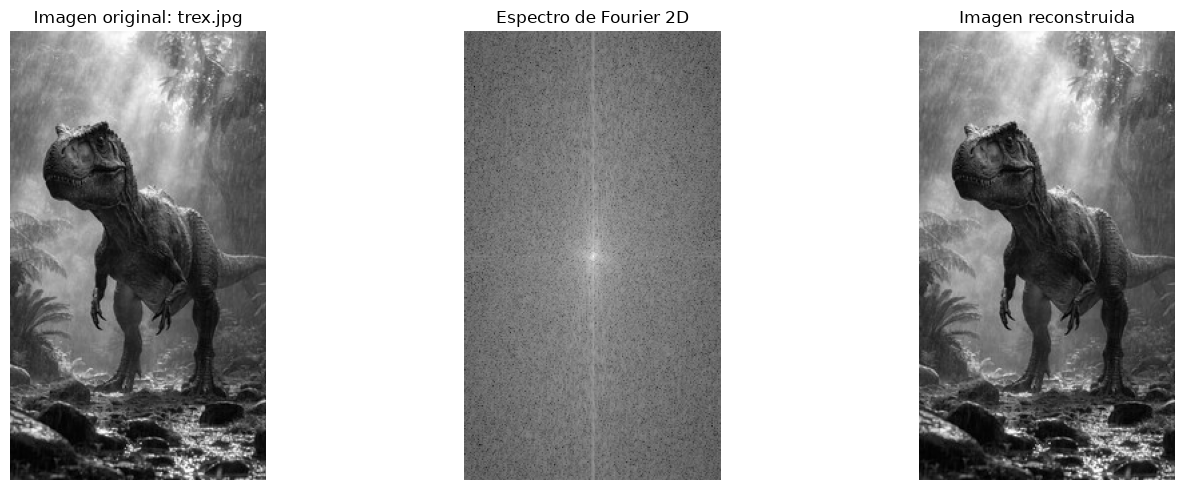

In [15]:
# Calcular la FFT 
from scipy.fft import fft2, ifft2, fftshift

F_imagen = fft2(imagen)

espectro = np.log1p(np.abs(fftshift(F_imagen)))
imagen_reconstruida = np.real(ifft2(F_imagen))

#Graficos
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen original: trex.jpg')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(espectro, cmap='gray')
plt.title('Espectro de Fourier 2D')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(imagen_reconstruida, cmap='gray')
plt.title('Imagen reconstruida')
plt.axis('off')

plt.tight_layout()
plt.show()

Sí, se obtiene un resultado prácticamente igual. La imagen reconstruida conserva los detalles y la formade la original, la transformada inversa de Fourier permitio recuperar la imagen 